# Phase 4 (Modeling)

## 4.1 Modeling goals

Goal is to build two or three different regression models (ml or dl methods) that can: 

- Predict the **price** of a used car based on its features
- Predict **daysonmarket** which indicates how long the car will stay listed before it will be sold. It tells us how easy it will be to sell spesific cars. 

## 4.2 Modeling techniques

We chose **regression models** to achieve our goals. Both targets (price and daysonmarket) are continuous numerical values. 

- Predict the price -> regression 
- Predict the days on market -> regression 

 

Two different regression models will be used: 
1. **LightGBM**
   - Handles millions of rows effeciently and sparse one-hot encoding
   - Apparently great for price prediction
   - suitable for skewed target like daysonmarket 
2. **Ridge**, Regularized linear regression
   - Fast to train
   - Useful to compare against nonlinear more complpex models 


***NOTE***: to use lightgbm need to add it to your python kernel with following steps:
- open anaconda prompt
- type "conda env list" to see your environments and either change the base or dedicated ml one if you have one
- type "conda activate ***" where * is your env you selected
- type "conda install lightgbm optuna"

In [11]:
# imports done like this
from lightgbm import LGBMRegressor
import lightgbm as lgb
from sklearn.linear_model import Ridge

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.model_selection import RandomizedSearchCV
import optuna


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [ ]:
df = pd.read_csv("../../cars_df_processed.csv")

## 4.3 Target variables and features

Preprocessed dataset 'cars_df_processed.csv' can be found in groups Teams channel 

Models are trained separately for each target (two regression problems) 
- **Input features (X)** 
- **Target variables (y)** 
    - 'price' 
    - 'daysonmarket' 

In [24]:
X = df.drop(columns=["price", "daysonmarket"])

# Target variables
y_price = df["price"]
y_days = df["daysonmarket"]

## 4.4 Train/test split and scaling

We split the data into training and test sets: 
- **Train/test split**: 80% training, 20% test
- Random state 

Scaling rules: 
- Use **standardscaler** instead of minmax
- Scale only numerical columns + CITYFREQ
- Don't scale one-hot encoded columns
- Don't scale target variables y (price and daysonmarket) 

Apply scaling **after** the train/test split:
- 'fit_transfrom' on 'X_train'
- 'transfrom' on 'X_test' 

In [25]:
# Numerical columns only, no one-hot encoded or target variables
num_cols = ["fuel_tank_volume", "height", "horsepower", "length", 
            "seats", "mileage", "savings_amount", "dealer_rating", "torque",
            "wheelbase", "width", "year", "combined_fuel_economy", "legroom",
            "major_options_count", "car_age", "mileage_per_year", "city_freq"
            ]

X_train, X_test, y_train_price, y_test_price = train_test_split(
    X, y_price, test_size=0.2, random_state=42          # y_price
)

y_train_days = y_days.loc[y_train_price.index]
y_test_days = y_days.loc[y_test_price.index]            # y_days

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])      # scale only numerical columns
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])            # scale only numerical columns

## 4.5 Hyperparameters

Test different hyperparameter values for both models: 

(Change y (price or daysonmarket) to change targets) 

- Ridge
  - alpha (small=more flexible, large=more conservative) testing [0.1, 1, 10, 100]
  - Which has the lowest error? 
- LightGBM
  - learning_rate (how fast the model learns, small=safer&slower, large=quick&risky) [0.05, 0.1, 0.2]
  - n_estimators (how many trees are built, small=fater&less accurate, large=slower&better) [100, 300, 500]
  - max_depth (how deep&complex each tree is, small=simple, large=complex) [-1, 10, 20]
  - num_leaves (shape of tree, large=complex) [31, 63] 

### Finding best hyperparameters for ridge models

Ridge_price

In [26]:
from sklearn.model_selection import RandomizedSearchCV

ridge_price = Ridge()
param_dist = {
    "alpha": np.logspace(-6,6,100)
}

ridge_price_search = RandomizedSearchCV(
    estimator=ridge_price,
    param_distributions=param_dist,
    n_iter=30,
    scoring="neg_mean_squared_error",
    cv=3,
    n_jobs=1,
    random_state=42
)

ridge_price_search.fit(X_train_scaled, y_train_price)
best_ridge_price_alpha = ridge_price_search.best_params_["alpha"]


In [27]:
print(best_ridge_price_alpha)

0.12328467394420659


Training ridge_price with best params

In [28]:
final_ridge_price = Ridge(alpha=best_ridge_price_alpha)
final_ridge_price.fit(X_train_scaled, y_train_price)

ridge_preds = final_ridge_price.predict(X_test_scaled)

Ridge_days

In [29]:
ridge_days = Ridge()
param_dist = {
    "alpha": np.logspace(-6,6,100)
}

ridge_days_search = RandomizedSearchCV(
    estimator=ridge_days,
    param_distributions=param_dist,
    n_iter=30,
    scoring="neg_mean_squared_error",
    cv=3,
    n_jobs=1,
    random_state=42
)

ridge_days_search.fit(X_train_scaled, y_train_days)
best_ridge_days_alpha = ridge_days_search.best_params_["alpha"]


In [30]:
print(best_ridge_days_alpha)

4.641588833612782


Training ridge_days with best params

In [31]:
final_ridge_days = Ridge(alpha=best_ridge_days_alpha)
final_ridge_days.fit(X_train_scaled, y_train_days)

ridge_days_preds = final_ridge_days.predict(X_test_scaled)

### Finding best hyperparameters for lightbgm models

lgb_price

In [32]:
import optuna
import lightgbm as lgb

tune_fraction = 0.15
subset_idx = np.random.choice(X_train_scaled.shape[0], int(X_train_scaled.shape[0]*tune_fraction), replace=True)

X_tune = X_train_scaled.iloc[subset_idx]
y_tune = y_train_price.iloc[subset_idx]

X_tr, X_val, y_tr, y_val = train_test_split(X_tune, y_tune, test_size=0.2, random_state=42)

feature_names = [f"f{i}" for i in range(X_tr.shape[1])]

lgb_train = lgb.Dataset(X_tr, y_tr, feature_name=feature_names)
lgb_valid = lgb.Dataset(X_val, y_val, feature_name=feature_names)

def lgb_objective(trial):

        params = {
            "objective": "regression",
            "metric": "rmse",
            "verbosity": -1,
            "boosting_type": "gbdt",
            "feature_pre_filter": False,
            "num_leaves": trial.suggest_int("num_leaves", 16, 256),
            "learning_rate": trial.suggest_float("learning_rate", 1e-4, 0.2, log=True),
            "feature_fraction": trial.suggest_float("feature_fraction", 0.5, 1.0),
            "bagging_fraction": trial.suggest_float("bagging_fraction", 0.5, 1.0),
            "bagging_freq": trial.suggest_int("bagging_freq", 1, 10),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
            "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 20, 200)
        }

        model = lgb.train(
            params,
            lgb_train,
            valid_sets=[lgb_valid],
            num_boost_round=1000,
            callbacks=[lgb.early_stopping(stopping_rounds=50)]
        )

        preds = model.predict(X_val)
        return mean_squared_error(y_val, preds)

study_price = optuna.create_study(direction="minimize")
study_price.optimize(lgb_objective, n_trials=20)

best_lgb_price_params = {k: v for k, v in study_price.best_params.items()}
best_lgb_price_params.update({
        "objective": "regression",
        "metric": "rmse",
        "verbosity": -1,
        "feature_pre_filter": False
})


[I 2025-12-10 23:25:10,442] A new study created in memory with name: no-name-c704fb89-5ae9-44c9-ad18-ca6334824426


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[1000]	valid_0's rmse: 3415.56


[I 2025-12-10 23:25:17,765] Trial 0 finished with value: 11666078.757680465 and parameters: {'num_leaves': 41, 'learning_rate': 0.06832683936800946, 'feature_fraction': 0.9344497293564558, 'bagging_fraction': 0.6096507683860104, 'bagging_freq': 10, 'min_child_samples': 29, 'min_data_in_leaf': 100}. Best is trial 0 with value: 11666078.757680465.


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[1000]	valid_0's rmse: 12457.4


[I 2025-12-10 23:25:30,870] Trial 1 finished with value: 155187688.8526755 and parameters: {'num_leaves': 63, 'learning_rate': 0.0002384333302057389, 'feature_fraction': 0.7463287122450277, 'bagging_fraction': 0.9113115641238003, 'bagging_freq': 2, 'min_child_samples': 51, 'min_data_in_leaf': 100}. Best is trial 0 with value: 11666078.757680465.


...

[I 2025-12-10 23:29:13,664] Trial 17 finished with value: 11354231.495530222 and parameters: {'num_leaves': 175, 'learning_rate': 0.012923945978935283, 'feature_fraction': 0.6770651455385339, 'bagging_fraction': 0.8414315501980117, 'bagging_freq': 4, 'min_child_samples': 62, 'min_data_in_leaf': 62}. Best is trial 16 with value: 9972923.968144793.


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[999]	valid_0's rmse: 3159.22


[I 2025-12-10 23:29:29,557] Trial 18 finished with value: 9980665.624587098 and parameters: {'num_leaves': 238, 'learning_rate': 0.05521034576318594, 'feature_fraction': 0.7032487465218535, 'bagging_fraction': 0.6534140865568315, 'bagging_freq': 4, 'min_child_samples': 81, 'min_data_in_leaf': 74}. Best is trial 16 with value: 9972923.968144793.


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[1000]	valid_0's rmse: 4783.83


[I 2025-12-10 23:29:47,087] Trial 19 finished with value: 22885006.639740966 and parameters: {'num_leaves': 248, 'learning_rate': 0.002088706601092715, 'feature_fraction': 0.7132957194530837, 'bagging_fraction': 0.6582806357924801, 'bagging_freq': 3, 'min_child_samples': 82, 'min_data_in_leaf': 148}. Best is trial 16 with value: 9972923.968144793.


In [33]:
print(best_lgb_price_params)

{'num_leaves': 178, 'learning_rate': 0.07506969189725428, 'feature_fraction': 0.7160989641177603, 'bagging_fraction': 0.8190887005603753, 'bagging_freq': 4, 'min_child_samples': 61, 'min_data_in_leaf': 70, 'objective': 'regression', 'metric': 'rmse', 'verbosity': -1, 'feature_pre_filter': False}


Training lgb_price with best params

In [34]:
feature_names_full = [f"f{i}" for i in range(X_train_scaled.shape[1])]
lgb_train_full = lgb.Dataset(X_train_scaled, y_train_price, feature_name=feature_names_full)

final_lgb_price = lgb.train(
        best_lgb_price_params,
        lgb_train_full,
        num_boost_round=1000
)

lgb_price_preds = final_lgb_price.predict(X_test_scaled)

lbg_days

In [35]:
tune_fraction = 0.15
subset_idx = np.random.choice(X_train_scaled.shape[0], int(X_train_scaled.shape[0]*tune_fraction), replace=True)

X_tune = X_train_scaled.iloc[subset_idx]
y_tune = y_train_days.iloc[subset_idx]

X_tr, X_val, y_tr, y_val = train_test_split(X_tune, y_tune, test_size=0.2, random_state=42)

feature_names = [f"f{i}" for i in range(X_tr.shape[1])]

lgb_train = lgb.Dataset(X_tr, y_tr, feature_name=feature_names)
lgb_valid = lgb.Dataset(X_val, y_val, feature_name=feature_names)

def lgb_objective(trial):

        params = {
            "objective": "regression",
            "metric": "rmse",
            "verbosity": -1,
            "boosting_type": "gbdt",
            "feature_pre_filter": False,
            "num_leaves": trial.suggest_int("num_leaves", 16, 256),
            "learning_rate": trial.suggest_float("learning_rate", 1e-4, 0.2, log=True),
            "feature_fraction": trial.suggest_float("feature_fraction", 0.5, 1.0),
            "bagging_fraction": trial.suggest_float("bagging_fraction", 0.5, 1.0),
            "bagging_freq": trial.suggest_int("bagging_freq", 1, 10),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
            "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 20, 200)
        }

        model = lgb.train(
            params,
            lgb_train,
            valid_sets=[lgb_valid],
            num_boost_round=1000,
            callbacks=[lgb.early_stopping(stopping_rounds=50)]
        )

        preds = model.predict(X_val)
        return mean_squared_error(y_val, preds)

study_days = optuna.create_study(direction="minimize")
study_days.optimize(lgb_objective, n_trials=20)

best_lgb_days_params = {k: v for k, v in study_days.best_params.items()}
best_lgb_days_params.update({
        "objective": "regression",
        "metric": "rmse",
        "verbosity": -1,
        "feature_pre_filter": False
})


[I 2025-12-10 23:31:04,465] A new study created in memory with name: no-name-931d0b9f-71e0-4a98-85d4-29bb63c2a2f3


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[1000]	valid_0's rmse: 94.579


[I 2025-12-10 23:31:18,303] Trial 0 finished with value: 8945.182749209875 and parameters: {'num_leaves': 83, 'learning_rate': 0.0005162918781084267, 'feature_fraction': 0.5322540097560131, 'bagging_fraction': 0.8375364536405565, 'bagging_freq': 7, 'min_child_samples': 59, 'min_data_in_leaf': 196}. Best is trial 0 with value: 8945.182749209875.


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[1000]	valid_0's rmse: 84.3914


[I 2025-12-10 23:31:28,990] Trial 1 finished with value: 7121.900709448276 and parameters: {'num_leaves': 80, 'learning_rate': 0.0090189997587235, 'feature_fraction': 0.6328644905156449, 'bagging_fraction': 0.7523363932929084, 'bagging_freq': 10, 'min_child_samples': 5, 'min_data_in_leaf': 87}. Best is trial 1 with value: 7121.900709448276.


...

[I 2025-12-10 23:35:31,692] Trial 17 finished with value: 6718.91807957117 and parameters: {'num_leaves': 237, 'learning_rate': 0.06713879402435768, 'feature_fraction': 0.677386127590078, 'bagging_fraction': 0.8269567108869105, 'bagging_freq': 2, 'min_child_samples': 19, 'min_data_in_leaf': 127}. Best is trial 17 with value: 6718.91807957117.


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[1000]	valid_0's rmse: 82.131


[I 2025-12-10 23:35:52,524] Trial 18 finished with value: 6745.495707615758 and parameters: {'num_leaves': 254, 'learning_rate': 0.05036623840144128, 'feature_fraction': 0.6702088790532488, 'bagging_fraction': 0.8002064936133879, 'bagging_freq': 5, 'min_child_samples': 16, 'min_data_in_leaf': 127}. Best is trial 17 with value: 6718.91807957117.


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[1000]	valid_0's rmse: 82.2874


[I 2025-12-10 23:36:13,200] Trial 19 finished with value: 6771.214553258009 and parameters: {'num_leaves': 253, 'learning_rate': 0.0254400347031054, 'feature_fraction': 0.6615015309265471, 'bagging_fraction': 0.8108305632967412, 'bagging_freq': 6, 'min_child_samples': 16, 'min_data_in_leaf': 114}. Best is trial 17 with value: 6718.91807957117.


In [36]:
print(best_lgb_days_params)

{'num_leaves': 237, 'learning_rate': 0.06713879402435768, 'feature_fraction': 0.677386127590078, 'bagging_fraction': 0.8269567108869105, 'bagging_freq': 2, 'min_child_samples': 19, 'min_data_in_leaf': 127, 'objective': 'regression', 'metric': 'rmse', 'verbosity': -1, 'feature_pre_filter': False}


Training lgb_days with best params

In [37]:
feature_names_full = [f"f{i}" for i in range(X_train_scaled.shape[1])]
lgb_train_full = lgb.Dataset(X_train_scaled, y_train_days, feature_name=feature_names_full)

final_lgb_days = lgb.train(
        best_lgb_days_params,
        lgb_train_full,
        num_boost_round=1000
)

lgb_days_preds = final_lgb_days.predict(X_test_scaled)

## 4.6 Error metrics

Regression models will be evaluated with regression metrics: 
- **Mean ablsolute error** (MAE)
  - Calculates the average of the absolute differences between the predicted and actual values
  - Easy to interpret, doesn't show whther errors are due to over- or under-prediction 
- **Mean squared error (MSE) OR??????? root mean squared error (RMSE)**
  - MSE
    - Brings the metric back to the original scale of the data
    - Heavily penalizes larger errors
    - Easy to interpret, it is in same units as the target variable
    - Useful when we want to know how much our predictions deviate from the actual values
  - RMSE
    - How far on an average, the residuals are from zero
    - Useful when target variable spans a wide range of values i.e. when large errors are present and they drastically affect the models performance
    - Unlike MSE, it penalizes underestimations more than overestimations helps in making it ideal for situations where the model is predicting quantities that vary greatly in scale like predicting prices or population 

Choice: RMSE (Root Mean Squared Error)

Main reasons:

Same units as the target: RMSE expresses the error directly in euros (price) or days (days on market), making it easy to interpret.

Practicality: Since car prices and days on market vary widely, RMSE gives the average deviation in the same unit as the target.

Clear for reporting: MSE would be in squared units, which is harder to interpret; RMSE is intuitive and reader-friendly.


- **R2 (R-squared)**
  - Represents the proportion of the variance in the dependent variable that is predictable from the independetn variables i.e. how good the model fits the dependent variables
  - R2 value close to 1 indicates better fit, model explains most of the variance
  - R2 value close to 0 indicates that model does not explain much of the variability in the data 

MAE

We calculate the Mean Absolute Error (MAE) for each model and target.
MAE shows the average difference between predicted and actual values.
Lower MAE means better predictions.
Here, LightGBM predicts both price and days on market more accurately than Ridge.


In [40]:
# Ridge - price
mae_ridge_price = mean_absolute_error(y_test_price, ridge_preds)
print("Ridge - Price MAE:", mae_ridge_price)

# Ridge - daysonmarket (muokkaa nimi vastaamaan sinun Ridge -days ennustetta)
mae_ridge_days = mean_absolute_error(y_test_days, ridge_days_preds)
print("Ridge - Days on Market MAE:", mae_ridge_days)

# LightGBM - price
mae_lgb_price = mean_absolute_error(y_test_price, lgb_price_preds)
print("LightGBM - Price MAE:", mae_lgb_price)

# LightGBM - daysonmarket
mae_lgb_days = mean_absolute_error(y_test_days, lgb_days_preds)
print("LightGBM - Days on Market MAE:", mae_lgb_days)


Ridge - Price MAE: 4731.170170158754
Ridge - Days on Market MAE: 63.77900691321973
LightGBM - Price MAE: 1943.1302870259995
LightGBM - Days on Market MAE: 49.65066603516508


RMSE (Root Mean Squared Error)

RMSE shows the average prediction error in the same units as the target.
Lower values mean more accurate predictions.
LightGBM performs better than Ridge for both price and days on market.

In [42]:
# Ridge - price
rmse_ridge_price = np.sqrt(mean_squared_error(y_test_price, ridge_preds))
print("Ridge - Price RMSE:", rmse_ridge_price)

# Ridge - daysonmarket
rmse_ridge_days = np.sqrt(mean_squared_error(y_test_days, ridge_days_preds))
print("Ridge - Days on Market RMSE:", rmse_ridge_days)

# LightGBM - price
rmse_lgb_price = np.sqrt(mean_squared_error(y_test_price, lgb_price_preds))
print("LightGBM - Price RMSE:", rmse_lgb_price)

# LightGBM - daysonmarket
rmse_lgb_days = np.sqrt(mean_squared_error(y_test_days, lgb_days_preds))
print("LightGBM - Days on Market RMSE:", rmse_lgb_days)


Ridge - Price RMSE: 6813.495366931139
Ridge - Days on Market RMSE: 99.36394330108664
LightGBM - Price RMSE: 2947.9072518985945
LightGBM - Days on Market RMSE: 82.41332760591462


R² Evaluation:

R² shows how much of the target’s variance the model explains.
LightGBM fits both price and days on market better than Ridge, especially for price.

In [43]:
# Ridge - price
r2_ridge_price = r2_score(y_test_price, ridge_preds)
print("Ridge - Price R²:", r2_ridge_price)

# Ridge - daysonmarket
r2_ridge_days = r2_score(y_test_days, ridge_days_preds)
print("Ridge - Days on Market R²:", r2_ridge_days)

# LightGBM - price
r2_lgb_price = r2_score(y_test_price, lgb_price_preds)
print("LightGBM - Price R²:", r2_lgb_price)

# LightGBM - daysonmarket
r2_lgb_days = r2_score(y_test_days, lgb_days_preds)
print("LightGBM - Days on Market R²:", r2_lgb_days)


Ridge - Price R²: 0.7878136913337308
Ridge - Days on Market R²: 0.10106717880973959
LightGBM - Price R²: 0.9602803824018351
LightGBM - Days on Market R²: 0.381607091338945


Summary of Model Performance for Error Metrics:

The models were evaluated using MAE, RMSE, and R²:

MAE shows the average absolute error.

RMSE shows the average error magnitude in the same units as the target, penalizing larger errors more.

R² shows how much of the target’s variance the model explains.

Across all metrics, LightGBM performs better than Ridge for both price and days on market, especially for predicting car prices. Therefore, LightGBM is the preferred model for these tasks.

## 4.7 Test the model and visualize results

For both target variables (price and daysonmarket) and each model (ridge, lightGBM) we will: 
- Train and test
- Show evaluation metrics results
- Visualize model performance
  1. Scatter plots
     - 'actual vs predicted' (shows how well the model is performing, ideal is when points are close to diagonal line)
     - 'actual vs predicted with r-squared values'
  2. Histogram
     - 'histogram of residual' (differences between observed and predicted values of data, ideal when residual is normally distributed)
  3. Feature importance plot (lightGBM)
     - (shows which variables influence the models predictions the most i.e. which features matter most) 

Scatter plots

Points close to the red diagonal line indicate accurate predictions.
LightGBM predictions are closer to the line for both price and days on market, showing it is more accurate than Ridge.

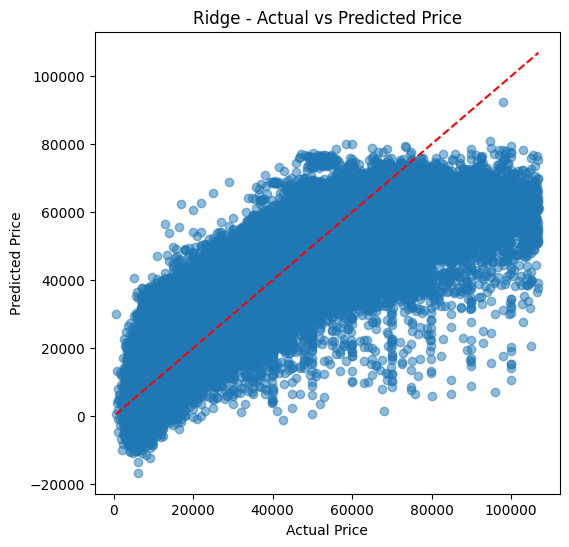

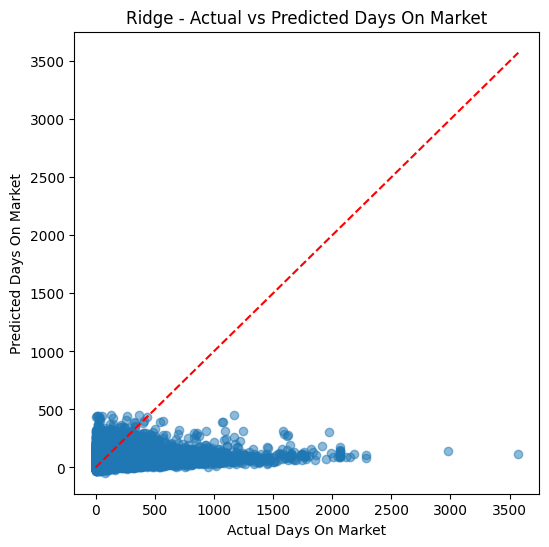

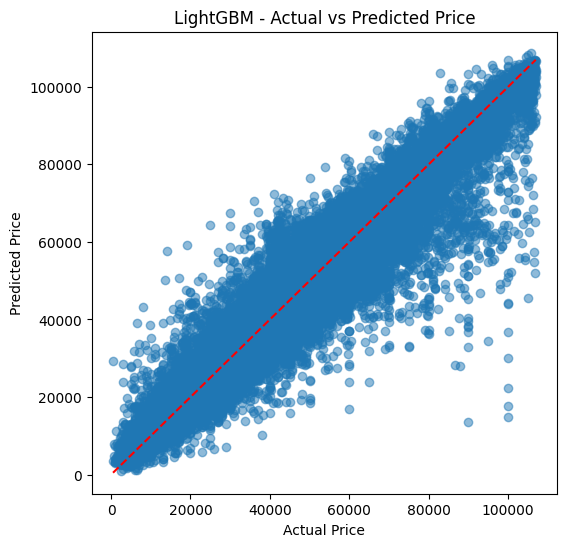

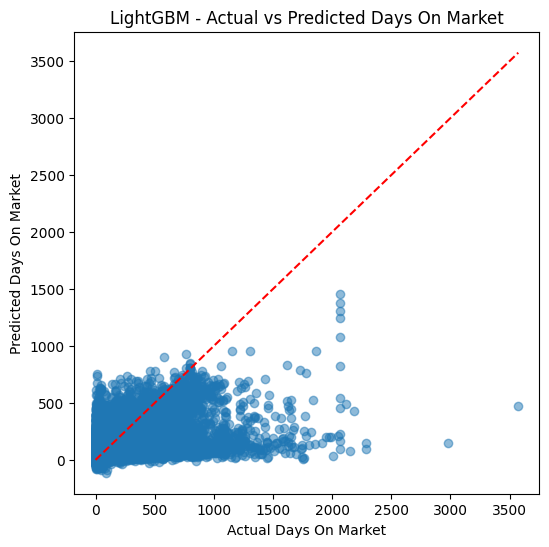

In [44]:
models_preds = {
    "Ridge": {"price": ridge_preds, "days on market": ridge_days_preds},
    "LightGBM": {"price": lgb_price_preds, "days on market": lgb_days_preds}
}

# Loop through models and targets
for model_name, targets in models_preds.items():
    for target_name, preds in targets.items():
        if target_name == "price":
            y_true = y_test_price
        else:  # "days on market"
            y_true = y_test_days
        
        plt.figure(figsize=(6,6))
        plt.scatter(y_true, preds, alpha=0.5)
        plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
        plt.xlabel(f'Actual {target_name.title()}')
        plt.ylabel(f'Predicted {target_name.title()}')
        plt.title(f'{model_name} - Actual vs Predicted {target_name.title()}')
        plt.show()


Histogram

Residuals are centered around zero, with errors spreading on both sides.
This shows the models do not systematically over- or under-predict, and smaller spread indicates better accuracy (LightGBM is tighter than Ridge).

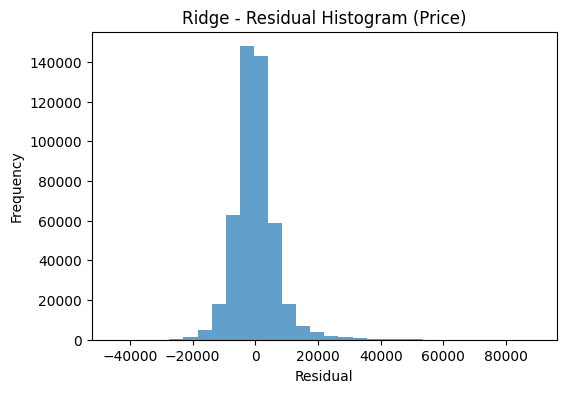

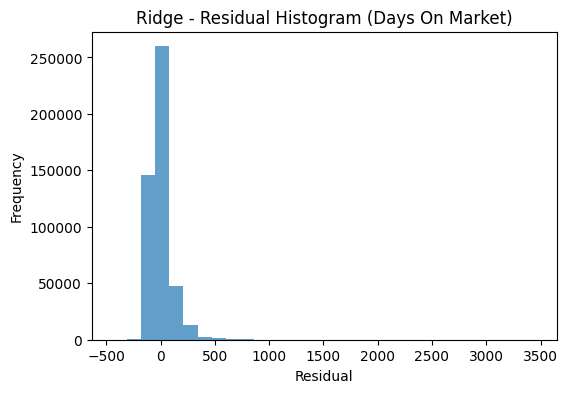

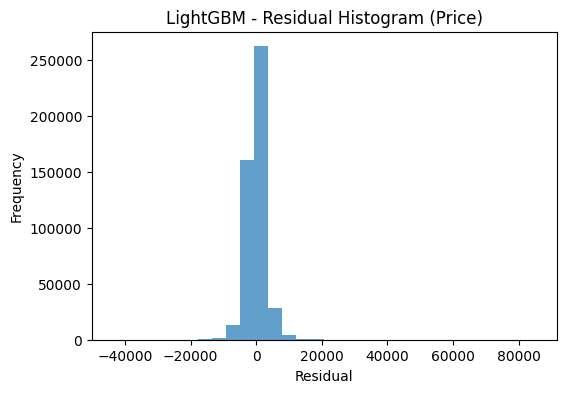

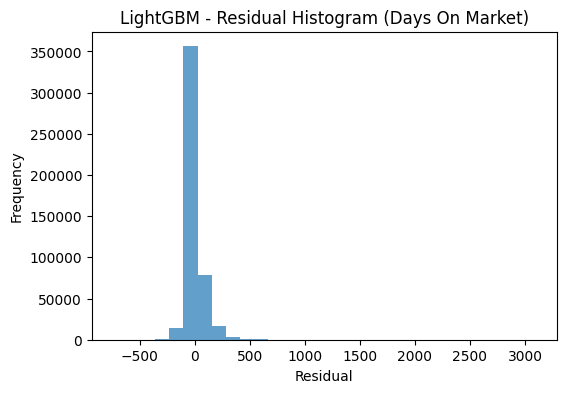

In [45]:
models_preds = {
    "Ridge": {"price": ridge_preds, "days on market": ridge_days_preds},
    "LightGBM": {"price": lgb_price_preds, "days on market": lgb_days_preds}
}

# Loop through models and targets
for model_name, targets in models_preds.items():
    for target_name, preds in targets.items():
        y_true = y_test_price if target_name == "price" else y_test_days
        residuals = y_true - preds
        
        plt.figure(figsize=(6,4))
        plt.hist(residuals, bins=30, alpha=0.7)
        plt.xlabel('Residual')
        plt.ylabel('Frequency')
        plt.title(f'{model_name} - Residual Histogram ({target_name.title()})')
        plt.show()


Feature Importance (LightGBM)

Shows which features influence predictions the most.
For price and days on market, the top features indicate the car attributes that drive model decisions.

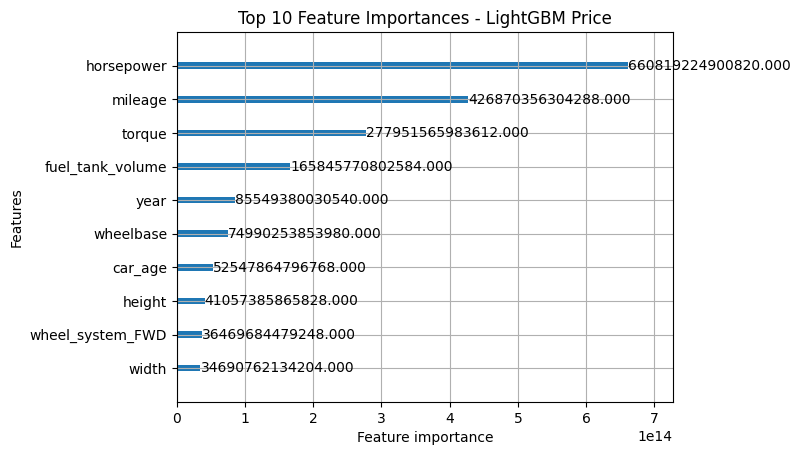

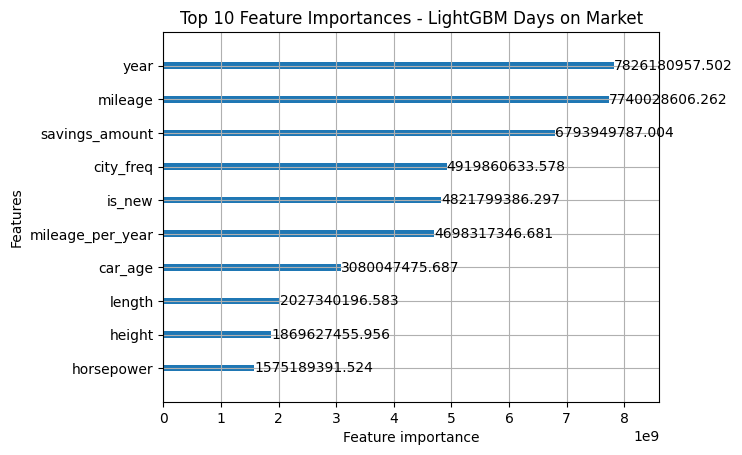

In [48]:
# Feature Importance for Price
feature_names = X_train.columns
lgb_train_full_price = lgb.Dataset(X_train, y_train_price, feature_name=list(feature_names))
final_lgb_price = lgb.train(best_lgb_price_params, lgb_train_full_price, num_boost_round=1000)
lgb.plot_importance(final_lgb_price, max_num_features=10, importance_type='gain')
plt.title('Top 10 Feature Importances - LightGBM Price')
plt.show()

# Feature Importance for Days on Market
lgb_train_full_days = lgb.Dataset(X_train, y_train_days, feature_name=list(feature_names))
final_lgb_days = lgb.train(best_lgb_days_params, lgb_train_full_days, num_boost_round=1000)
lgb.plot_importance(final_lgb_days, max_num_features=10, importance_type='gain')
plt.title('Top 10 Feature Importances - LightGBM Days on Market')
plt.show()


## Summary of Model Performance and Visualizations

# Error Metrics (Test Data):

Ridge – Price: MAE 4731, RMSE 6813, R² 0.79

Ridge – Days on Market: MAE 64, RMSE 99, R² 0.10

LightGBM – Price: MAE 1943, RMSE 2948, R² 0.96

LightGBM – Days on Market: MAE 50, RMSE 82, R² 0.38

# Residual Analysis:

Residuals are centered around zero and spread on both sides → models do not systematically over- or under-predict.

LightGBM residuals are narrower → smaller errors than Ridge, especially for Price.

# Feature Importance (LightGBM):

Price: most important features are Horsepower and Mileage.

Days on Market: most important feature is Year.

Larger gain values indicate higher impact on predictions.

# Conclusion:

LightGBM is more accurate than Ridge for both targets.

Visualizations confirm this: closer points to diagonal in scatter plots, tighter residuals, and meaningful feature importance.